# Inside a robot dataset

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/wnukmat/robot-learning-notebooks/blob/main/notebooks/4_data_and_hardware/01_inside_a_robot_dataset.ipynb) &nbsp; Guide note: [guide-robot-data](https://www.matthewwnuk.com/guide-robot-data.html)

What is actually in a demonstration dataset? This notebook opens LIBERO-10, the dataset used for
figures throughout the guide: 379 demonstrations of ten tasks. It looks at the fields, the cameras,
episode lengths, how sub-tasks can be read off the gripper signal, and the alignment between images
and actions that every training loader depends on.

In [1]:
# Setup. On Colab this installs the small helper package; where it is already installed it does nothing.
import importlib.util, subprocess, sys
if importlib.util.find_spec("guide_utils") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/wnukmat/robot-learning-notebooks"])

In [2]:
import numpy as np, matplotlib.pyplot as plt
from guide_utils import data, style
style.use()
d = data.libero(); tasks = data.libero_tasks(); A, S, EP, TK = d["action"], d["state"], d["episode"], d["task"]
eps = np.unique(EP); length = np.array([(EP == e).sum() for e in eps]); ep_task = np.array([TK[EP == e][0] for e in eps])
print(f"{len(eps)} episodes, {len(A):,} steps at 10 per second = {len(A) / 36000:.1f} hours of robot time")
for k, v in d.items(): print(f"  {k:8s} {v.shape}  {v.dtype}")
print(); [print(f"task {i + 1:2d} ({(ep_task == i).sum()} episodes): {t}") for i, t in tasks.items()]

379 episodes, 101,469 steps at 10 per second = 2.8 hours of robot time
  action   (101469, 7)  float32
  state    (101469, 8)  float32
  episode  (101469,)  int64
  task     (101469,)  int64
  frame    (101469,)  int64

task  1 (38 episodes): put the white mug on the left plate and put the yellow and white mug on the right plate
task  2 (36 episodes): put the white mug on the plate and put the chocolate pudding to the right of the plate
task  3 (34 episodes): put the yellow and white mug in the microwave and close it
task  4 (41 episodes): turn on the stove and put the moka pot on it
task  5 (43 episodes): put both the alphabet soup and the cream cheese box in the basket
task  6 (33 episodes): put both the alphabet soup and the tomato sauce in the basket
task  7 (29 episodes): put both moka pots on the stove
task  8 (49 episodes): put both the cream cheese box and the butter in the basket
task  9 (35 episodes): put the black bowl in the bottom drawer of the cabinet and close it
task 10

[None, None, None, None, None, None, None, None, None, None]

## Two cameras

The scene camera gives context. The wrist camera moves with the gripper and gives a close view of the grasp.

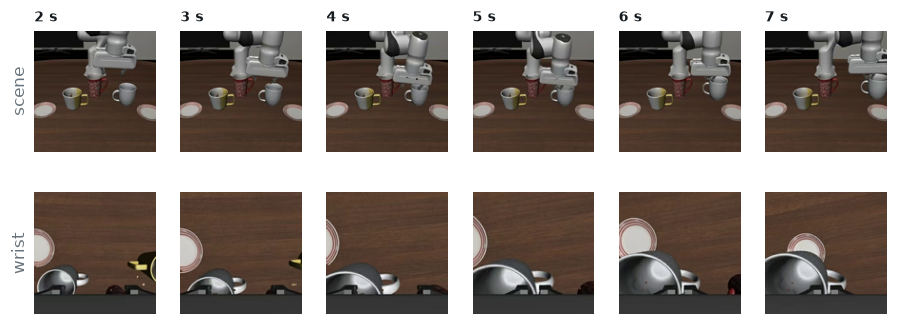

In [3]:
seq = data.libero_sequences(); fig, ax = plt.subplots(2, 6, figsize=(10, 3.5))
for c, t in enumerate(range(0, 60, 10)):
    ax[0, c].imshow(seq["scene"][0, t]); ax[1, c].imshow(seq["wrist"][0, t]); ax[0, c].set_title(f"{t / 10 + 2:.0f} s", fontsize=9); style.bare(ax[0, c]); style.bare(ax[1, c])
ax[0, 0].set_ylabel("scene"); ax[1, 0].set_ylabel("wrist"); plt.show()

## Episode lengths

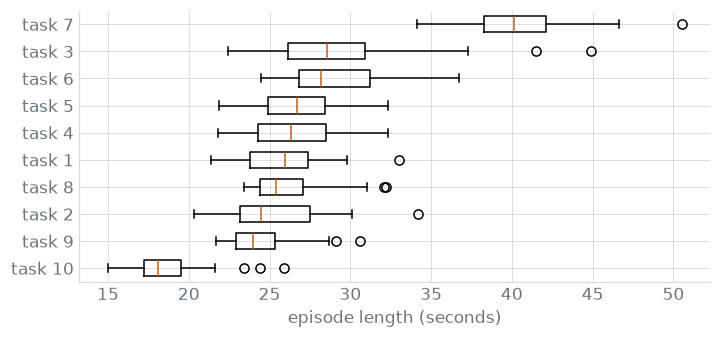

shortest 15 s, median 26 s, longest 50 s


In [4]:
order = np.argsort([np.median(length[ep_task == t]) for t in range(10)]); plt.figure(figsize=(7.4, 3.2))
plt.boxplot([length[ep_task == t] / 10 for t in order], vert=False, widths=0.6); plt.yticks(range(1, 11), [f"task {t + 1}" for t in order]); plt.xlabel("episode length (seconds)"); plt.show()
print(f"shortest {length.min() / 10:.0f} s, median {np.median(length) / 10:.0f} s, longest {length.max() / 10:.0f} s")

## One episode, start to finish

The hand's position, and the gripper. The moments the gripper command switches divide the episode into
sub-tasks, with no extra labels needed.

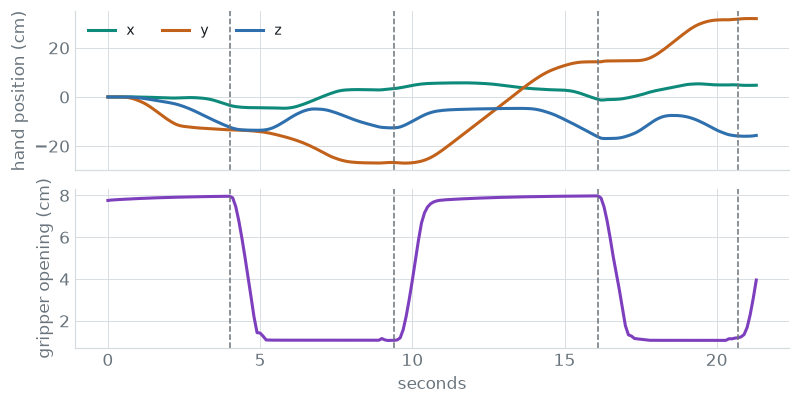

instruction: put the white mug on the left plate and put the yellow and white mug on the right plate
gripper switches at [ 4.   9.4 16.1 20.7] seconds


In [5]:
m = EP == 0; s, a = S[m], A[m]; t = np.arange(m.sum()) / 10; switches = np.flatnonzero(a[1:, 6] != a[:-1, 6]) + 1
fig, ax = plt.subplots(2, 1, figsize=(7.4, 3.8), sharex=True)
for k, n in enumerate("xyz"): ax[0].plot(t, (s[:, k] - s[0, k]) * 100, label=n)
ax[1].plot(t, (s[:, 6] - s[:, 7]) * 100, color=style.PURPLE)
for x in ax:
    for sw in switches: x.axvline(t[sw], color=style.MUTED, ls="--", lw=1)
ax[0].set_ylabel("hand position (cm)"); ax[0].legend(ncol=3, fontsize=9); ax[1].set_ylabel("gripper opening (cm)"); ax[1].set_xlabel("seconds"); plt.tight_layout(); plt.show()
print("instruction:", tasks[0]); print("gripper switches at", t[switches], "seconds")

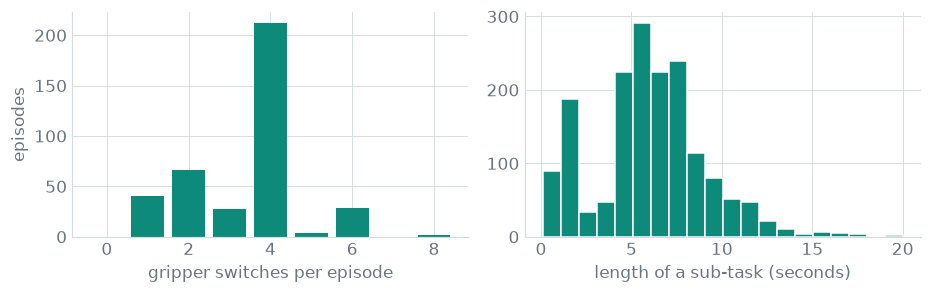

median sub-task: 5.9 s


In [6]:
n_sw, dur = [], []
for e in eps:
    g = A[EP == e][:, 6]; sw = np.flatnonzero(g[1:] != g[:-1]) + 1; n_sw.append(len(sw)); dur += list(np.diff(np.r_[0, sw, len(g)]) / 10)
fig, ax = plt.subplots(1, 2, figsize=(8.6, 2.8)); ax[0].bar(range(max(n_sw) + 1), np.bincount(n_sw)); ax[0].set_xlabel("gripper switches per episode"); ax[0].set_ylabel("episodes")
ax[1].hist(np.clip(dur, 0, 20), bins=20, color=style.TEAL, edgecolor="white"); ax[1].set_xlabel("length of a sub-task (seconds)"); plt.tight_layout(); plt.show()
print(f"median sub-task: {np.median(dur):.1f} s")

## Alignment: the bug that raises no error

A training example pairs an image with the action taken at that moment. If the loader is off by a few
frames, the policy is trained on actions that belong to a different image. How different is the action
a few steps later?

In [7]:
same = lambda k: EP[k:] == EP[:-k]; spread = A[:, :3].std(0).mean()
for k in (1, 2, 5, 10):
    diff = np.abs(A[k:, :3] - A[:-k, :3])[same(k)].mean(); flips = (A[k:, 6] != A[:-k, 6])[same(k)].mean()
    print(f"off by {k:2d} step{'s' if k > 1 else ' '}: position command differs by {diff / spread:.0%} of its typical size; gripper command differs {flips:.1%} of the time")

off by  1 step : position command differs by 8% of its typical size; gripper command differs 1.3% of the time
off by  2 steps: position command differs by 16% of its typical size; gripper command differs 2.6% of the time
off by  5 steps: position command differs by 38% of its typical size; gripper command differs 6.5% of the time
off by 10 steps: position command differs by 67% of its typical size; gripper command differs 12.9% of the time


One step of misalignment changes the label only slightly, which is exactly why it goes unnoticed.
Check alignment by plotting, not by reading the loss.

## Things to try

- Compute the total distance the hand travels in each episode. Which task needs the most motion?
- Find the episode whose length is furthest from its task's median, and plot its hand path.
- Estimate how much disk space the images would need uncompressed, and compare with a few megabytes of video.